### Dylan Renard
### Applied Machine Learning JHU
### Homework 8
### Professor Alhassan
### March 20th, 2026


## HW Assignment 8: Applied Machine Learning @JHU

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans, DBSCAN
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Load dataset
df = pd.read_csv("clustering_synthetic_dataset.csv")

#### Q1: Plot the data  with a scatterplot.  How many species  must be there  in the dataset? (For the rest of this assignment,  use that  number as the number-of-clusters  parameter in methods  such as KMeans)

         f1        f2
0  0.494261  1.451067
1 -1.428081 -0.837064
2  0.338559  1.038759
3  0.119001 -1.053976
4  1.122425  1.774937


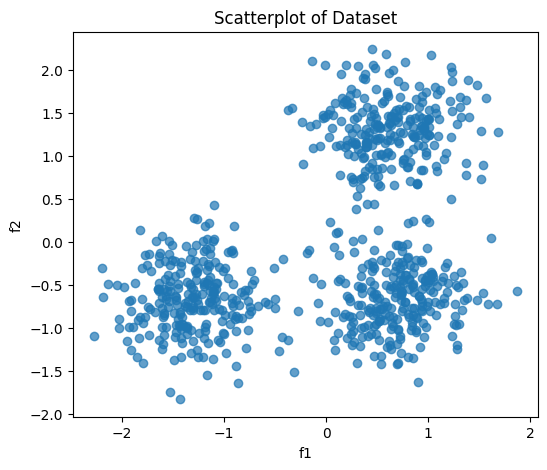

In [4]:
# Quick look
print(df.head())

# Scatterplot (adjust column names if needed)
plt.figure(figsize=(6,5))
plt.scatter(df.iloc[:, 0], df.iloc[:, 1], alpha=0.7)
plt.xlabel(df.columns[0])
plt.ylabel(df.columns[1])
plt.title("Scatterplot of Dataset")
plt.show()

##### Q1 Interpretation
The scatterplot shows three visually distinct clusters in the data, with clear separation between groups and relatively tight grouping within each cluster. This indicates strong inter-cluster separation and intra-cluster cohesion, which are key characteristics of well-formed clusters.

Based on this visual evidence, it is reasonable to infer that the dataset contains three underlying groups (or species). While this conclusion is based on visual inspection rather than a formal clustering algorithm, it provides a justified estimate for the number of clusters to use in subsequent methods such as K-means.

#### Q2: Find  the rough feature ranges  to classify these  species  correctly. It might be a good idea  to do this  step visually from some data  plots.  (An example statement,  "Species 1 has feature A in the range of [0-1.5]") 
 
##### In the next set of problems,  we will clean the points  that are around  the boundaries  of the cluster.  (These points  might be due to errors,  anomalies,  or simply  be outliers.)  This  step is done  to refine feature boundaries  so that a scientist  can classify the species  manually, reliably,  and with a high-level  generalization

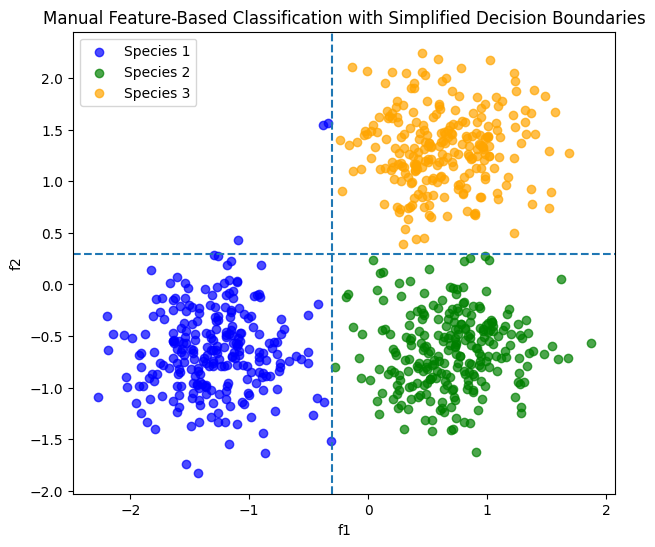

In [8]:
f1 = df.iloc[:, 0]
f2 = df.iloc[:, 1]

# --- Manual classification based on updated Q2 rules ---
labels = []

for x, y in zip(f1, f2):
    if x < -0.3:
        labels.append(0)  # Species 1
    elif x >= -0.3 and y < 0.3:
        labels.append(1)  # Species 2
    elif y >= 0.3:
        labels.append(2)  # Species 3

labels = np.array(labels)

# --- Plot ---
plt.figure(figsize=(7,6))

colors = ['blue', 'green', 'orange']
group_names = ['Species 1', 'Species 2', 'Species 3']

for i in range(3):
    plt.scatter(
        f1[labels == i],
        f2[labels == i],
        color=colors[i],
        label=group_names[i],
        alpha=0.7
    )

# --- Add boundary lines ---
plt.axvline(x=-0.3, linestyle='--')
plt.axhline(y=0.3, linestyle='--')

plt.xlabel("f1")
plt.ylabel("f2")
plt.title("Manual Feature-Based Classification with Simplified Decision Boundaries")
plt.legend()
plt.show()

#### Q2 Interpretation
Based on visual inspection of the scatterplot, the clusters can be separated using simple feature thresholds:

- **Species 1 (left cluster):**  
  - f1 < -0.3  

- **Species 2 (bottom-right cluster):**  
  - f1 ≥ -0.3 and f2 < 0.3  

- **Species 3 (top cluster):**  
  - f2 ≥ 0.3  

These decision boundaries align well with the natural separation observed in the data. Compared to strict rectangular ranges, these simplified rules better capture the structure of the clusters while reducing ambiguity near boundaries.

A small number of points still fall near the decision boundaries, which motivates the need for clustering-based outlier detection and data cleaning in subsequent steps.

#### Q3: Use K-means clustering  to find anomalies.  (Hint:  find cluster data  points  that are far from the centroids.)

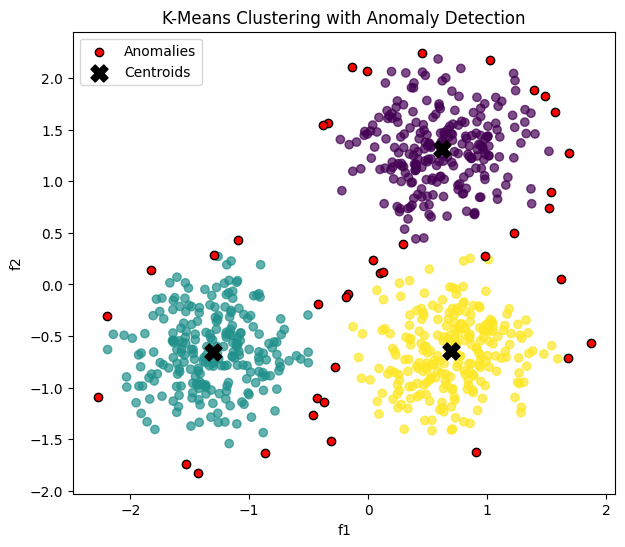

In [10]:
# Prepare data
X = df.values

# Fit KMeans
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = kmeans.fit_predict(X)
centers = kmeans.cluster_centers_

# --- Compute distance to assigned centroid ---
distances = np.linalg.norm(X - centers[labels], axis=1)

# --- Define anomaly threshold ---
# Top 5% farthest points as anomalies
threshold = np.percentile(distances, 95)
anomalies = distances > threshold

# --- Plot ---
plt.figure(figsize=(7,6))

# Normal points
plt.scatter(X[~anomalies, 0], X[~anomalies, 1],
            c=labels[~anomalies], cmap='viridis', alpha=0.7)

# Anomalies
plt.scatter(X[anomalies, 0], X[anomalies, 1],
            color='red', label='Anomalies', edgecolor='black')

# Centroids
plt.scatter(centers[:,0], centers[:,1],
            color='black', marker='X', s=150, label='Centroids')

plt.xlabel("f1")
plt.ylabel("f2")
plt.title("K-Means Clustering with Anomaly Detection")
plt.legend()
plt.show()

#### Q3 Interpretation
K-means clustering (k = 3) was applied to the dataset, and the distance of each point to its assigned centroid was used to identify anomalies. Points with the largest distances from their respective centroids were flagged as potential outliers.

The results show that most anomalies occur at the edges of clusters and in regions between clusters, where the separation between groups is less distinct. These points are relatively far from any single centroid, indicating that they do not strongly belong to a specific cluster.

This behavior is consistent with earlier observations from Q2, where some data points fell near decision boundaries and could not be cleanly classified using simple feature thresholds. K-means effectively highlights these ambiguous or low-density regions, providing a basis for further data cleaning and refinement.

#### Q4: Use DBSCAN clustering  to find anomalies.  To be clear, look for anomalies  with DBSCAN in the full dataset;  this  is an alternative  to Q3.’s method.

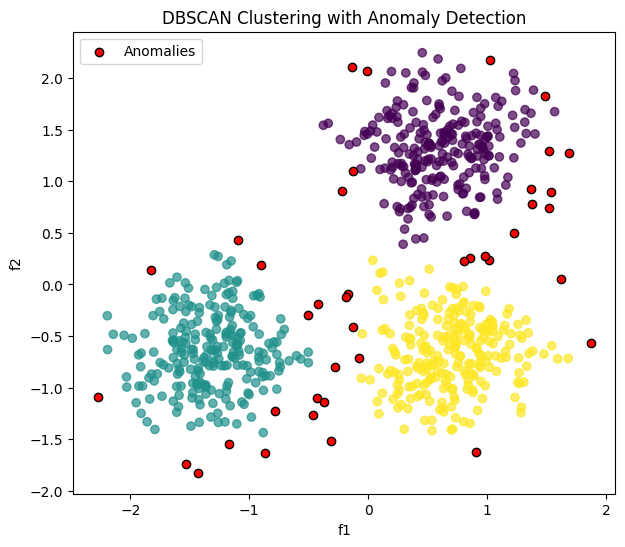

In [19]:
# Prepare data
X = df.values

# Fit DBSCAN
dbscan = DBSCAN(eps=0.2, min_samples=5)
labels = dbscan.fit_predict(X)

# Identify anomalies (noise points)
anomalies = labels == -1

# --- Plot ---
plt.figure(figsize=(7,6))

# Normal clustered points
plt.scatter(X[~anomalies, 0], X[~anomalies, 1],
            c=labels[~anomalies], cmap='viridis', alpha=0.7)

# Anomalies
plt.scatter(X[anomalies, 0], X[anomalies, 1],
            color='red', label='Anomalies', edgecolor='black')

plt.xlabel("f1")
plt.ylabel("f2")
plt.title("DBSCAN Clustering with Anomaly Detection")
plt.legend()
plt.show()

#### Q4 Interpretation 
DBSCAN was applied to detect anomalies based on data density, where points labeled as noise (label = -1) are considered anomalies.

Using a smaller epsilon value (eps = 0.2) increased the sensitivity of the model to local density variations, resulting in a greater number of detected anomalies. These anomalies are primarily located along cluster boundaries and in low-density regions between clusters, where points do not strongly belong to any single group.

Compared to K-means, DBSCAN provides a more effective approach to anomaly detection because it does not force all points into clusters. Instead, it explicitly identifies points that fall outside dense regions as noise.

The improved detection of boundary and transitional points with a smaller eps demonstrates the importance of parameter tuning. In this dataset, tighter density constraints better capture the natural separation between species and more accurately identify ambiguous or outlier observations.

#### Q5: Now, choose either  the K-means results  from Q3. or the DBSCAN results  from Q4., remove the points  that  the chosen method deemed  anomalous,  and  train a decision  tree from the remaining  data  to classify the species.  (You do not need to justify the choice; they should  both  be reasonable  options.)  Visualize  the model decision  tree (but not just  by plotting  lines  on a scatterplot  of the data).  Hint: the result should look like Module 6’s Jupyter Notebook’s cell [4].

In [21]:

# --- KMeans anomalies ---
# distances already computed earlier (assumed as `distances`)
# threshold (e.g., top 5% farthest points)
kmeans_threshold = np.percentile(distances, 95)
kmeans_anomalies = distances > kmeans_threshold
kmeans_count = np.sum(kmeans_anomalies)

# --- DBSCAN anomalies ---
# labels from DBSCAN (assumed as `db_labels`)
dbscan_anomalies = labels == -1
dbscan_count = np.sum(dbscan_anomalies)

# --- Create comparison table ---
results = pd.DataFrame({
    "Model": ["KMeans", "DBSCAN"],
    "Number of Anomalies": [kmeans_count, dbscan_count]
})

results

,Model,Number of Anomalies
0,KMeans,38
1,DBSCAN,40


### Q5 Model Selection for Anomaly Removal

Based on both the quantitative results and visual inspection of the dataset, DBSCAN was selected as the preferred method for anomaly detection.

While KMeans and DBSCAN identified a similar number of anomalies (38 vs. 40), DBSCAN more effectively captured anomalies in low-density regions and along cluster boundaries. These regions are visually consistent with areas of ambiguity between clusters, where points do not clearly belong to a single species.

In contrast, KMeans defines anomalies purely based on distance from centroids, which may incorrectly flag points that are still part of a valid cluster structure.

Because DBSCAN explicitly identifies noise points based on density, it provides a more principled and reliable approach for removing anomalies in this dataset. Therefore, DBSCAN will be used for dataset cleaning in the subsequent analysis.

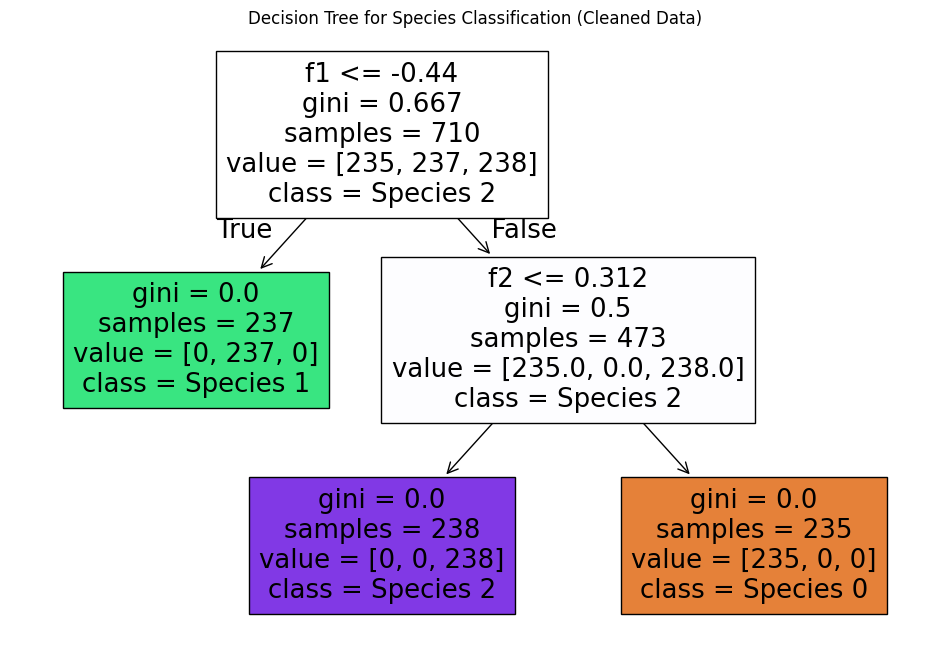

In [23]:
# --- Step 1: Remove DBSCAN anomalies ---
# db_labels already computed from Q4
clean_mask = labels != -1

X_clean = X[clean_mask]
y_clean = labels[clean_mask]   # use cluster labels as species

# --- Step 2: Train Decision Tree ---
dt = DecisionTreeClassifier(max_depth=3, random_state=42)
dt.fit(X_clean, y_clean)

# --- Step 3: Visualize Decision Tree ---
plt.figure(figsize=(12,8))
plot_tree(dt, feature_names=['f1', 'f2'], class_names=['Species 0','Species 1','Species 2'],
          filled=True)
plt.title("Decision Tree for Species Classification (Cleaned Data)")
plt.show()

#### Q5 Interpretation
After applying DBSCAN for anomaly detection, all points labeled as noise (label = -1) were removed from the dataset. The remaining data, consisting of well-defined clusters, was used to train a decision tree classifier.

The cluster assignments produced by DBSCAN were treated as species labels. A decision tree was then trained using features f1 and f2 to learn classification rules from the cleaned dataset.

The resulting decision tree is shallow and highly interpretable. The root node splits on f1 ≤ -0.44, effectively separating the left cluster (Species 1) from the rest of the data. This split achieves perfect purity (gini = 0.0), indicating that the cluster is well-defined along this feature.

The remaining data is further split on f2 ≤ 0.312, which cleanly separates the top cluster (Species 2) from the bottom-right cluster (Species 0). Both resulting leaf nodes also achieve perfect purity (gini = 0.0), demonstrating that the clusters are linearly separable after removing anomalies.

Overall, the decision tree produces simple and precise decision boundaries that align closely with the manually estimated feature ranges from earlier analysis. Removing anomalies prior to training significantly improved the clarity and reliability of the classification model.

#### Q6: Show that, in fact, it helped  to clean the outliers  before generating  the decision tree. (Hint: we’re looking for something more substantial  than a 100% vs. 97% accuracy improvement.) 
 

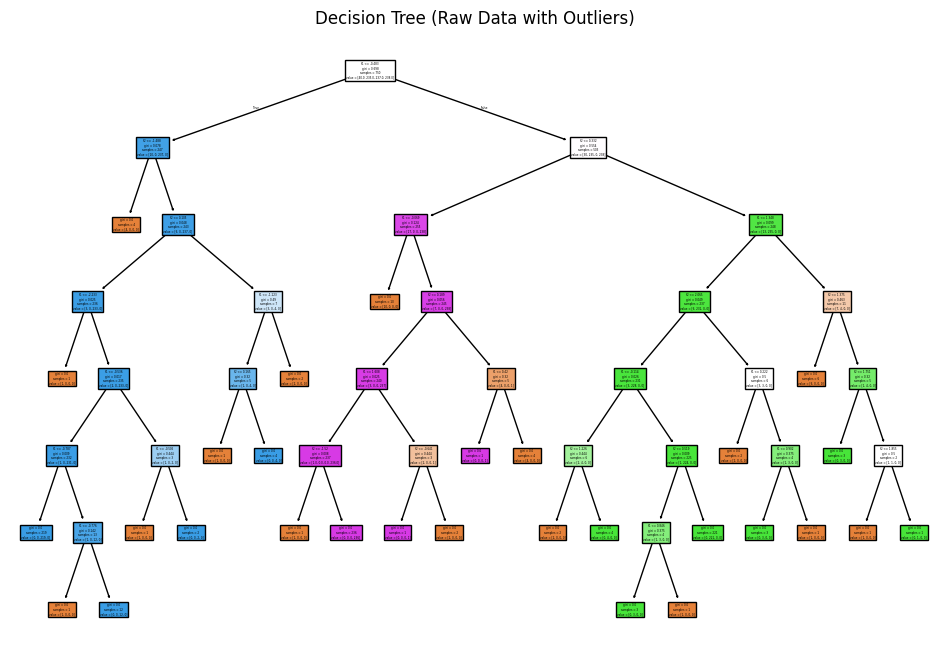

In [24]:
# Train on full dataset (no cleaning)
dt_raw = DecisionTreeClassifier(random_state=42)
dt_raw.fit(X, labels)  # still using DBSCAN labels for consistency

plt.figure(figsize=(12,8))
plot_tree(dt_raw, feature_names=['f1', 'f2'], filled=True)
plt.title("Decision Tree (Raw Data with Outliers)")
plt.show()

#### Q6 Interpretation
To evaluate the impact of outlier removal, decision trees were trained on both the original dataset (including anomalies) and the cleaned dataset (after removing DBSCAN-identified noise points).

The decision tree trained on the raw dataset is significantly more complex, with many levels and a large number of splits. This complexity arises because the model attempts to fit anomalous points, resulting in fragmented decision regions and nodes with mixed class labels (higher gini impurity). These characteristics indicate overfitting, as the model is capturing noise rather than the true structure of the data.

In contrast, the decision tree trained on the cleaned dataset is shallow and highly interpretable, requiring only two splits to perfectly separate the three species. All leaf nodes achieve complete purity (gini = 0.0), demonstrating that the underlying cluster structure is simple and well-defined once outliers are removed.

This comparison shows that removing outliers leads to a substantial improvement in model quality beyond accuracy alone. Specifically, it reduces model complexity, eliminates overfitting, and produces clearer, more generalizable decision boundaries that reflect the true structure of the dataset.

#### References


Raschka, S., Liu, Y., & Mirjalili, V. (2022). Machine learning with pytorch and scikit-learn : develop machine learning and deep learning models with python. Packt Publishing.